# Lab 05: deret waktu dan data panel

**Durasi:** 90 menit

Tujuan: menguji stasioneritas, meramal dengan ARIMA, menguji
kointegrasi, dan menaksir model data panel.



**Pengayaan pilihan:** pengujian ramalan inflasi Indonesia (30 sampai 40 menit). Waktu ini di luar durasi materi inti.

<!-- alur_belajar -->

**Kaitan dengan materi lain**

| Bekal sebelumnya | Fokus notebook ini | Hasil yang dibawa berikutnya |
|---|---|---|
| Sesi 05 untuk deret waktu dan bagian panel Sesi 06; Lab 05 menggabungkan keduanya. | Terapkan ARIMA, kointegrasi/ECM, dan panel pada contoh terbimbing. | Lab 06 memindahkan kebiasaan ini ke seri dan panel ekonomi yang sumbernya dicatat. |

**Posisi dalam alur workshop.** Menambah dimensi waktu dan individu ke
model. Lab 06 menutup dengan data Indonesia asli.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**. Paket `linearmodels` dipasang di sel berikutnya
(butuh internet sekali saja).



**Alur sesi:** kita menggunakan urutan waktu dan pengamatan berulang. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan data aktual, ramalan, dan pola antarunit.

Jalankan contoh terbimbing sampai hasilnya muncul, kemudian lengkapi sel latihan yang masih berupa komentar.

<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `set_theme, rcParams, dan label grafik` | Membuat grafik terbaca konsisten. | Tema, ukuran huruf, DPI, judul, xlabel/ylabel, legend, dan tight_layout. | Mengubah tampilan, bukan nilai model; plt.show() menampilkan grafik di notebook. |

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. Stasioneritas dan ARIMA

Data `data/indeks_harga_simulasi.csv`: indeks harga 50 periode yang naik terus.
Langkah pertama selalu melihat plot.



Nama kolom inflasi pada CSV simulasi ini menunjukkan seri indeks harga. Nilai levelnya bukan inflasi YoY dalam persen; pembedaan ini penting sebelum membaca hasil ADF dan ramalan.

<!-- kamus_variabel:indeks_harga_simulasi.csv -->

### Kenali data: Deret harga/inflasi simulasi

**Data:** `data/indeks_harga_simulasi.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `inflasi` | Deret level bertendensi naik, dicontohkan sebagai IHK pada sumber. | Level/indeks simulasi; bukan otomatis persen inflasi | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.read_csv` | Membaca CSV atau TSV menjadi tabel. | Alamat berkas; sep="\t" memilih pemisah tab pada TSV. | DataFrame; periksa nama kolom dan ukuran sebelum analisis. |
| `head` | Melihat contoh isi tabel. | Tanpa angka menampilkan lima baris; head(10) menampilkan sepuluh. | Cuplikan awal, bukan ringkasan seluruh data. |
| `dropna` | Membentuk sampel dengan kolom yang dibutuhkan terisi. | Pilih kolom model dahulu, lalu dropna(); subset membatasi kolom pemeriksaan. | Tabel baru; baris terbuang dapat mengubah komposisi sampel. |
| `diff dan pct_change` | Membuat perubahan antarperiode. | diff() selisih level; pct_change() perubahan relatif, dikali 100 untuk persen. | Baris pertama kosong; selisih inflasi persen bersatuan poin persentase. |
| `fit` | Mengestimasi parameter model. | scikit-learn: fit(X_train, y_train); paket statistik: fit() sesudah model menerima data. | Parameter dipelajari dari sampel yang diberikan; data uji tidak dipakai untuk melatih. |
| `summary, pvalues, dan bse` | Membaca ringkasan hasil statistik. | Objek hasil fit; bse adalah standard error dan pvalues adalah p-value. | Nilai p menguji hipotesis sesuai asumsi, bukan ukuran besarnya dampak atau bukti kausalitas. |
| `adfuller` | Menguji hipotesis akar unit. | Seri yang diurutkan; regression menentukan komponen konstan/tren; autolag memilih lag. | [0] statistik dan [1] p-value; p kecil mendukung penolakan akar unit untuk spesifikasi uji ini. |
| `ARIMA` | Memodelkan pola deret waktu. | Seri latihan, order=(p,d,q): lag AR, differencing, dan lag MA. | Model deret waktu; pemilihan orde dan pengujian ramalan perlu mengikuti waktu. |
| `get_forecast dan conf_int` | Membuat ramalan beserta intervalnya. | steps jumlah periode setelah akhir latihan; alpha mengatur tingkat interval. | predicted_mean dan interval; ketidakpastian bergantung pada model serta asumsi. |

In [4]:
inflasi = pd.read_csv(URL_DATA + "indeks_harga_simulasi.csv")

inflasi.head()

,obs,inflasi
0,1,100.5
1,2,101.2
2,3,101.8
3,4,102.5
4,5,103.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

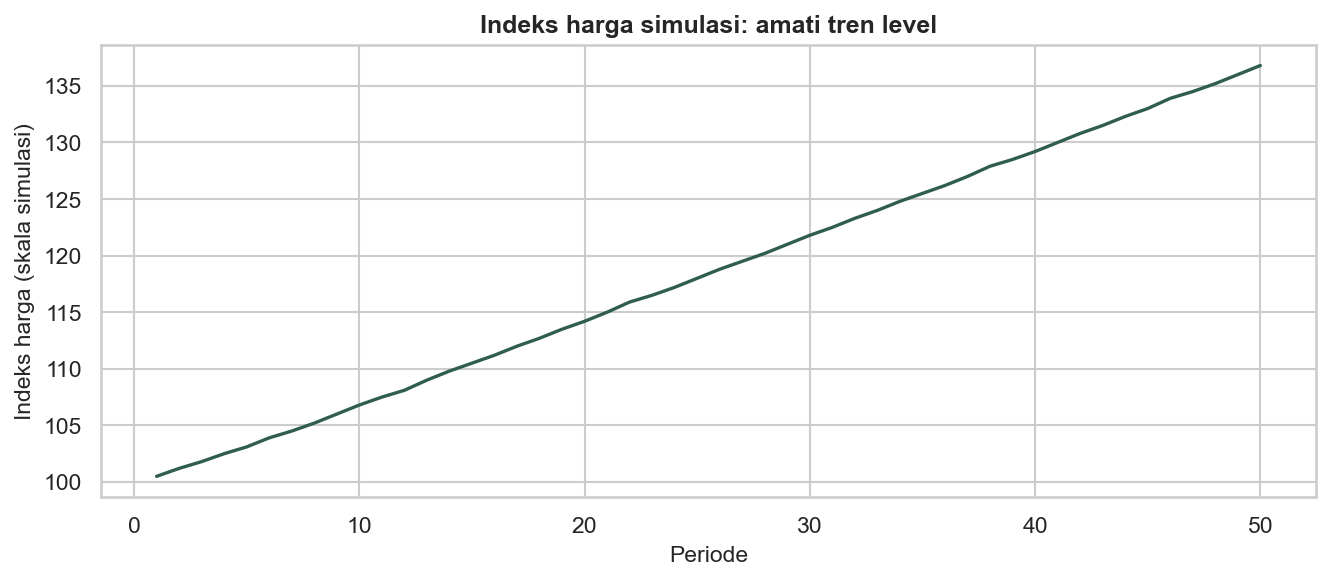

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(inflasi["obs"], inflasi["inflasi"], lw=1.6)
plt.title("Indeks harga simulasi: amati tren level")
plt.xlabel("Periode")
plt.ylabel("Indeks harga (skala simulasi)")
plt.tight_layout()
plt.show()

**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

In [6]:
from statsmodels.tsa.stattools import adfuller

p_level = adfuller(inflasi["inflasi"])[1]
p_diff = adfuller(inflasi["inflasi"].diff().dropna())[1]
print(f"ADF di level          : p = {p_level:.4f}")
print(f"ADF setelah selisih   : p = {p_diff:.4f}")

ADF di level          : p = 0.8192
ADF setelah selisih   : p = 0.0000


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_32800\2772567399.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_level = adfuller(inflasi["inflasi"])[1]
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_32800\2772567399.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_diff = adfuller(inflasi["inflasi"].diff().dropna())[1]


### Membaca hasil

Di level, p-value besar: data tidak stasioner (ada tren). Setelah satu
kali selisih, p-value kecil: sudah stasioner. Kesimpulan: pakai d = 1.

Model ARIMA(1,1,0) artinya: satu kali selisih, satu komponen AR.



In [7]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(inflasi["inflasi"], order=(1, 1, 0)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                inflasi   No. Observations:                   50
Model:                 ARIMA(1, 1, 0)   Log Likelihood                  28.907
Date:                Sun, 25 Oct 2026   AIC                            -53.813
Time:                        23:43:01   BIC                            -50.030
Sample:                             0   HQIC                           -52.378
                                 - 50                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9850      0.025     38.966      0.000       0.935       1.035
sigma2         0.0168      0.004      4.494      0.000       0.009       0.024
Ljung-Box (L1) (Q):                  13.72   Jarque-

Ramalan inflasi 5 periode ke depan:
[137.59 138.36 139.13 139.88 140.62]


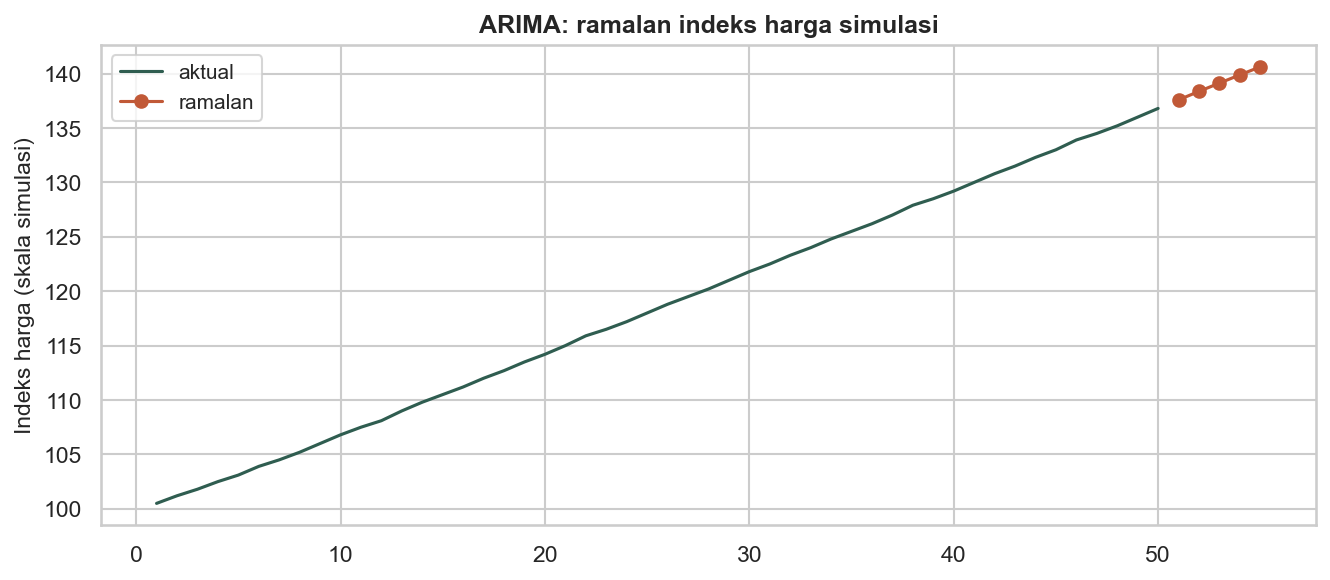

In [8]:
ramalan = model.get_forecast(steps=5)
print("Ramalan inflasi 5 periode ke depan:")
print(np.asarray(ramalan.predicted_mean).round(2))

plt.figure(figsize=(9, 4))
plt.plot(inflasi["obs"], inflasi["inflasi"], label="aktual")
masa_depan = np.arange(51, 56)
plt.plot(masa_depan, np.asarray(ramalan.predicted_mean), marker="o", label="ramalan")
plt.legend()
plt.title("ARIMA: ramalan indeks harga simulasi")
plt.ylabel("Indeks harga (skala simulasi)")
plt.tight_layout()
plt.show()

**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

## 2. Kointegrasi dan ECM

Data `data/konsumsi_pendapatan_tahunan.csv`. Dua variabel yang sama-sama
tidak stasioner bisa tetap berjalan bersama dalam jangka panjang.



<!-- kamus_variabel:konsumsi_pendapatan_tahunan.csv -->

### Kenali data: Konsumsi dan pendapatan runtun waktu

**Data:** `data/konsumsi_pendapatan_tahunan.csv`. **Satu baris:** satu tahun berurutan pada data simulasi.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun` | `Tahun` | Nomor tahun dalam urutan simulasi, bukan tahun kalender. | 1, 2, 3, ... | Penanda waktu |
| `Konsumsi_Y` | `konsumsi` | Nilai konsumsi pada periode tersebut. | Skala uang tidak dirinci | Y: target |
| `Pendapatan_X` | `pendapatan` | Nilai pendapatan pada periode yang sama. | Skala uang tidak dirinci | X: penjelas |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada data awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_konsumsi` | Logaritma alami nilai konsumsi. | Skala logaritma |
| `ln_pendapatan` | Logaritma alami nilai pendapatan. | Skala logaritma |
| `d_konsumsi` | Selisih log konsumsi dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `d_pendapatan` | Selisih log pendapatan dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `ect` | Error Correction Term: penyimpangan dari hubungan jangka panjang pada periode sebelumnya. | Residual log periode sebelumnya |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `rename` | Memperjelas nama kolom tanpa mengganti angka. | columns berisi pasangan nama lama dan nama baru. | Tabel dengan nama kolom baru; simpan kembali bila ingin dipakai sel berikutnya. |
| `pd.Series` | Menyusun satu kolom bernama atau koefisien berlabel. | Nilai dan index sebagai label; name memberi nama kolom. | Series; label membantu mencocokkan koefisien, prediksi, dan baris asal. |
| `loc dan iloc` | Memilih baris atau kolom secara jelas. | loc memakai label atau kondisi; iloc memakai posisi mulai 0; dua titik berarti seluruh rentang. | Bagian tabel; pertahankan indeks agar y dan prediksi sejajar. |
| `shift` | Membuat nilai masa lalu atau lag. | shift(1) mengambil satu baris sebelumnya; shift(12) dua belas baris sebelumnya. | Nilai awal kosong; urutkan dan pastikan frekuensi waktunya teratur dahulu. |
| `np.log dan np.exp` | Mengubah skala log alami dan mengembalikannya. | log hanya untuk nilai positif; exp mengembalikan skala dari log. | Interpretasi koefisien mengikuti bentuk model; exp(prediksi log) belum mengoreksi bias rata-rata. |
| `LinearRegression` | Menyiapkan regresi linear dengan scikit-learn. | fit_intercept=True adalah bawaan; X tabel dua dimensi, y satu target. | Estimator yang belum dilatih; koefisien baru tersedia setelah fit. |
| `predict` | Menghitung prediksi dari model yang sudah dilatih. | Tabel X baru dengan nama dan urutan fitur seperti saat fit. | Satu prediksi tiap baris; ketepatan pada data uji tetap harus diukur. |
| `coef_ dan intercept_` | Membaca kemiringan dan intersep model scikit-learn. | Atribut tanpa tanda kurung; urutan coef_ mengikuti kolom X. | Linear: perubahan prediksi y per satu unit X, dengan fitur lain tetap; logit memakai skala log-odds. |
| `sm.add_constant` | Menambahkan kolom intersep untuk pelengkap statistik. | X yang sama; has_constant="add" meminta kolom konstan. | Matriks X uji; scikit-learn sudah menghitung intersep sendiri sehingga tidak perlu kolom ini. |
| `sm.OLS` | Menghitung standard error dan pengujian regresi linear. | Urutan OLS(y, X_uji), lalu fit(); X_uji mencakup intersep. | Hasil inferensi pada sampel yang sama; model prediksi utama tetap scikit-learn. |
| `coint` | Menguji hubungan jangka panjang antarseri. | Dua seri level yang sesuai syarat integrasi; trend menetapkan komponen deterministik. | [1] p-value; hasil mendukung analisis kointegrasi dengan spesifikasi yang dipilih. |
| `subplots, scatter, dan plot` | Membuat ruang grafik lalu menampilkan hubungan atau pola waktu. | figsize ukuran; scatter untuk titik, plot untuk garis; sumbu dan satuan diberi label. | Titik menunjukkan pengamatan; garis mengikuti urutan X sehingga data perlu diurutkan bila perlu. |
| `axhline dan axvline` | Memberi patokan pada grafik. | y untuk garis horizontal, x untuk garis vertikal; linestyle mengatur pola garis. | Contoh: residual nol, periode program, atau batas latihan/uji; bukan hasil estimasi tambahan. |

In [9]:
from statsmodels.tsa.stattools import coint

makro = pd.read_csv(URL_DATA + "konsumsi_pendapatan_tahunan.csv")
makro = makro.rename(columns={"Konsumsi_Y": "konsumsi", "Pendapatan_X": "pendapatan"})

makro.head()

,Tahun,konsumsi,pendapatan
0,1,100.5,120.2
1,2,102.1,122.5
2,3,104.3,125.1
3,4,103.8,124.8
4,5,106.5,128.4


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [10]:
makro["ln_konsumsi"] = np.log(makro["konsumsi"])
makro["ln_pendapatan"] = np.log(makro["pendapatan"])

print("ADF level:")
print("  ln(konsumsi)  :", round(adfuller(makro["ln_konsumsi"])[1], 4))
print("  ln(pendapatan):", round(adfuller(makro["ln_pendapatan"])[1], 4))

ADF level:
  ln(konsumsi)  : 0.0232
  ln(pendapatan): 0.0128


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_32800\3276321719.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("  ln(konsumsi)  :", round(adfuller(makro["ln_konsumsi"])[1], 4))
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_32800\3276321719.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("  ln(pendapatan):", round(adfuller(makro["ln_pendapatan"])[1], 

**Batas contoh simulasi ini.** ADF dengan konstanta pada log kedua seri
memberi p sekitar 0,023 dan 0,013: akar unit sudah ditolak pada level.
Jadi hasil coint di bawah tidak cukup untuk menyatakan kedua seri I(1)
terkointegrasi. Perhitungan berikut memperagakan bentuk persamaan jangka
panjang dan komponen ECM, bukan bukti empiris kointegrasi yang sah.
Untuk penelitian, tetapkan tren/konstanta berdasarkan teori dan grafik,
periksa orde integrasi, lalu gunakan uji kointegrasi yang sesuai.



In [11]:
p_kointe = coint(makro["ln_konsumsi"], makro["ln_pendapatan"])[1]
print(f"\nUji kointegrasi: p = {p_kointe:.4f}")
print("ECM berikut adalah demonstrasi; syarat I(1) belum terpenuhi pada contoh ini.")


Uji kointegrasi: p = 0.0001
ECM berikut adalah demonstrasi; syarat I(1) belum terpenuhi pada contoh ini.


In [12]:
sampel_model_lr = makro[["ln_konsumsi", "ln_pendapatan"]].dropna()
X_model_lr = sampel_model_lr[["ln_pendapatan"]]
y_model_lr = sampel_model_lr["ln_konsumsi"]

model_lr = LinearRegression()
model_lr.fit(X_model_lr, y_model_lr)

koefisien_model_lr = pd.Series(model_lr.coef_, index=X_model_lr.columns)
koefisien_model_lr.loc["Intercept"] = model_lr.intercept_

prediksi_model_lr = pd.Series(model_lr.predict(X_model_lr), index=y_model_lr.index)
residu_model_lr = y_model_lr - prediksi_model_lr
print("Persamaan jangka panjang:")
print(koefisien_model_lr.round(3))

Persamaan jangka panjang:
ln_pendapatan    0.875
Intercept        0.420
dtype: float64


### Lihat hasil model: Log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

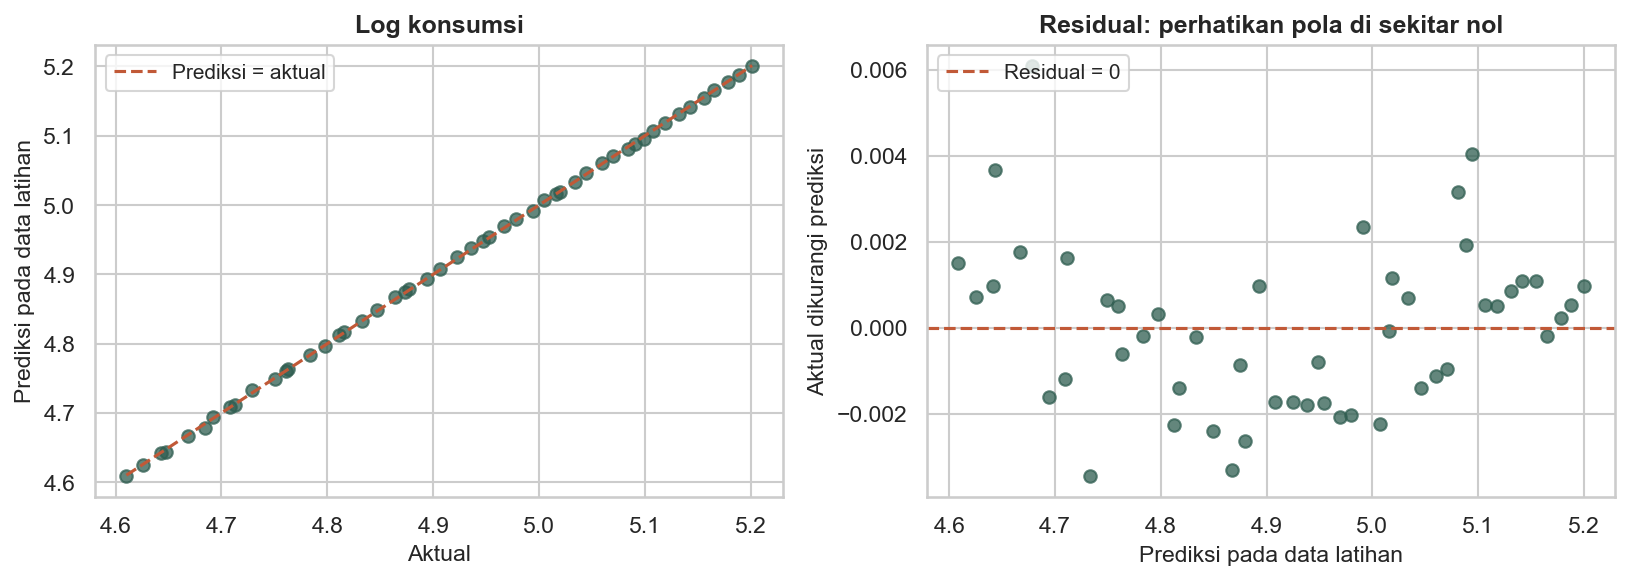

In [13]:
prediksi_visual = model_lr.predict(X_model_lr)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_lr, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_lr.min(), y_model_lr.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Log konsumsi")
axes[1].scatter(prediksi_visual, y_model_lr - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

In [14]:
# Siapkan komponen ECM: selisih untuk efek jangka pendek
makro["d_konsumsi"] = makro["ln_konsumsi"].diff()
makro["d_pendapatan"] = makro["ln_pendapatan"].diff()
# ECT = residual jangka panjang periode sebelumnya (koreksi ketidakseimbangan)
makro["ect"] = residu_model_lr.shift(1)

sampel_model_ecm = makro[["d_konsumsi", "d_pendapatan", "ect"]].dropna()
X_model_ecm = sampel_model_ecm[["d_pendapatan", "ect"]]
y_model_ecm = sampel_model_ecm["d_konsumsi"]

model_ecm = LinearRegression()
model_ecm.fit(X_model_ecm, y_model_ecm)

koefisien_model_ecm = pd.Series(model_ecm.coef_, index=X_model_ecm.columns)
koefisien_model_ecm.loc["Intercept"] = model_ecm.intercept_

### Lihat hasil model: Perubahan log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

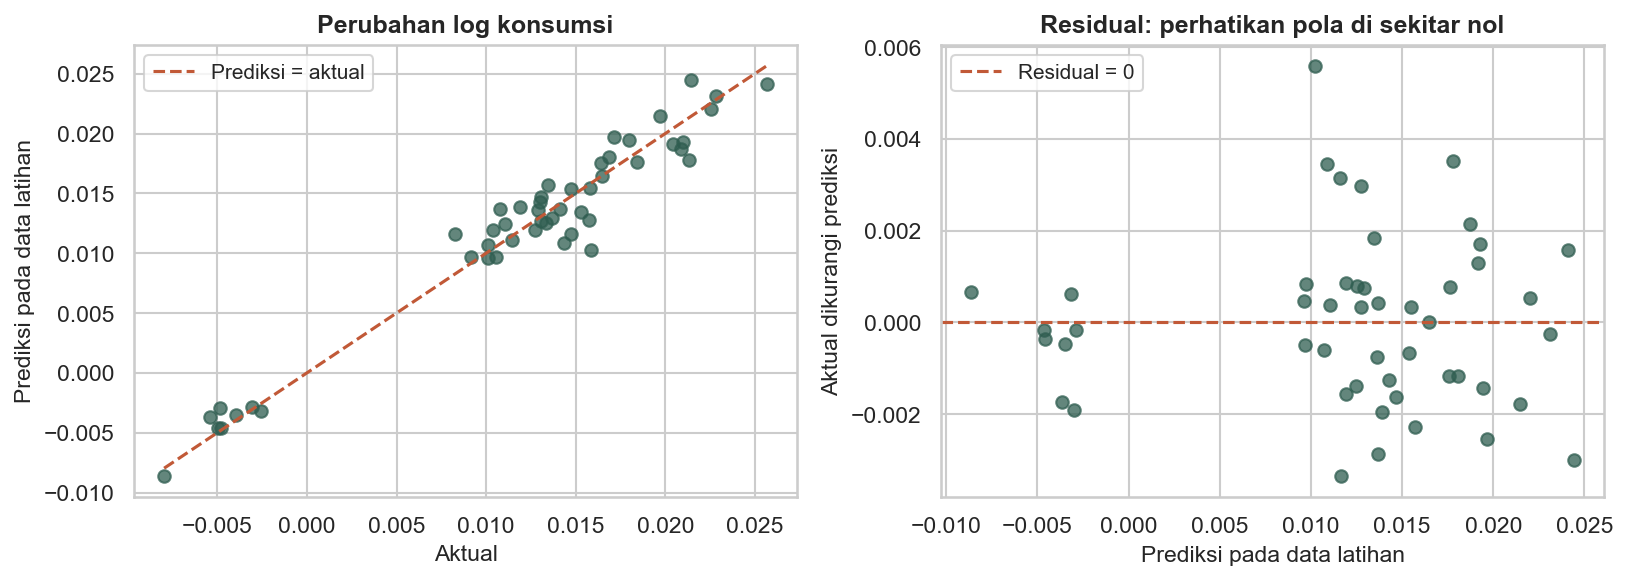

In [15]:
prediksi_visual = model_ecm.predict(X_model_ecm)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_ecm, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_ecm.min(), y_model_ecm.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Perubahan log konsumsi")
axes[1].scatter(prediksi_visual, y_model_ecm - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [16]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model_ecm = sm.add_constant(X_model_ecm, has_constant="add")
X_uji_model_ecm = X_uji_model_ecm.rename(columns={"const": "Intercept"})
uji_model_ecm = sm.OLS(y_model_ecm, X_uji_model_ecm).fit()
print("\nECM:")
print(koefisien_model_ecm.round(3))
print(uji_model_ecm.pvalues.round(4))


ECM:
d_pendapatan    0.870
ect            -0.705
Intercept       0.000
dtype: float64
Intercept       0.9321
d_pendapatan    0.0000
ect             0.0000
dtype: float64


### Membaca hasil

Koefisien `ect` = -0,70 dan signifikan. Artinya 70 persen
ketidakseimbangan periode sebelumnya dikoreksi pada periode ini, menuju
keseimbangan jangka panjang.



## 3. Data panel

Data `data/panel_padi.csv`: 5 petak sawah x 10 musim. Hasil panen
dijelaskan pupuk dan curah hujan. Dengan struktur panel, kita bisa
memisahkan pengaruh yang melekat pada tiap petak.



<!-- kamus_variabel:panel_padi.csv -->

### Kenali data: Panel hasil panen padi

**Data:** `data/panel_padi.csv`. **Satu baris:** satu petak sawah pada satu musim tanam.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `FarmID` | Kode petak sawah yang diamati berulang. | Nomor identitas lahan | Penanda, bukan besaran ekonomi |
| `Season` | Urutan musim tanam. | Musim tanam ke-1, ke-2, ... | Penanda waktu |
| `Yield_Y` | Jumlah gabah yang dihasilkan oleh petak sawah. | Ton gabah; bukan otomatis ton per hektar | Y: target |
| `Fertilizer_X1` | Banyaknya pupuk yang digunakan. | Kilogram (kg) | X: penjelas |
| `Rainfall_X2` | Banyaknya curah hujan pada musim tanam. | Milimeter (mm) | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pivot` | Menyusun tabel lebar untuk perbandingan. | index menentukan baris; columns menentukan kolom; values menentukan angka. | Satu nilai tiap pasangan; pasangan yang berulang perlu diringkas dahulu. |
| `set_index dan sort_index` | Menetapkan identitas atau waktu tiap baris. | Nama kolom indeks; panel memakai [unit, waktu]; sort_index() mengurutkan. | Tabel berindeks; identitas unit-waktu harus unik. |
| `cov_type pada fit` | Mengganti cara menghitung standard error. | HC3 untuk heteroskedastisitas; HAC dengan maxlags untuk ketergantungan waktu. | Pada OLS dengan X/y sama, koefisien tetap; standard error dan p-value dapat berubah. |
| `PanelOLS dan RandomEffects` | Memodelkan banyak unit yang diamati berulang. | Indeks [unit, waktu]; entity_effects=True untuk efek tetap unit; cov_type mengatur SE. | Koefisien panel; FE mengendalikan perbedaan unit yang tetap sepanjang waktu. |

In [17]:
from linearmodels.panel import PanelOLS

padi = pd.read_csv(URL_DATA + "panel_padi.csv")

padi.head()

,FarmID,Season,Yield_Y,Fertilizer_X1,Rainfall_X2
0,1,1,5.2,100,200
1,1,2,5.5,110,210
2,1,3,6.0,120,220
3,1,4,5.8,115,205
4,1,5,6.5,130,250


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [18]:
padi = padi.set_index(["FarmID", "Season"])
y = padi["Yield_Y"]
X = padi[["Fertilizer_X1", "Rainfall_X2"]]

fem = PanelOLS(y, X, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)
print(fem.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                Yield_Y   R-squared:                        0.9964
Estimator:                   PanelOLS   R-squared (Between):              0.9930
No. Observations:                  50   R-squared (Within):               0.9964
Date:                Sun, Oct 25 2026   R-squared (Overall):              0.9930
Time:                        23:43:03   Log-likelihood                    86.131
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      5943.0
Entities:                           5   P-value                           0.0000
Avg Obs:                      10.0000   Distribution:                    F(2,43)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):          8.293e+32
                            

### Lahan yang sama diamati pada beberapa musim

reset_index mengembalikan penanda lahan dan musim menjadi kolom sebelum digambar.

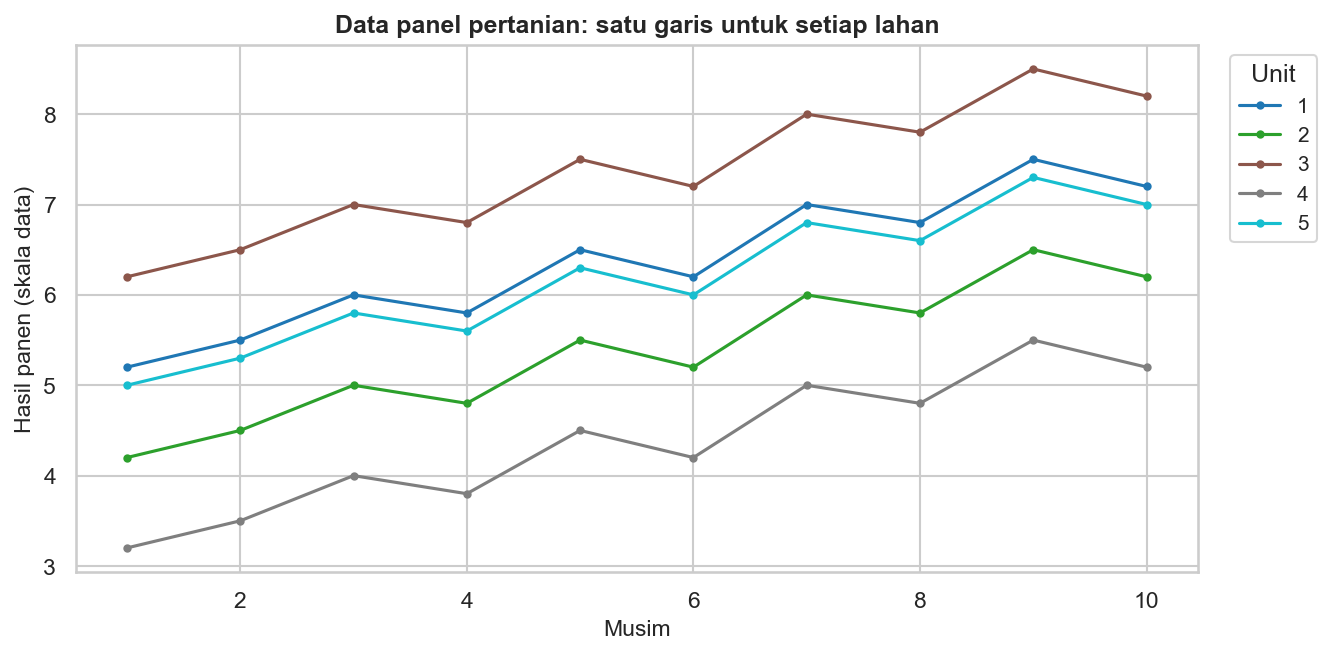

In [19]:
tabel_garis = padi.reset_index().pivot(index="Season", columns="FarmID", values="Yield_Y")
ax = tabel_garis.plot(colormap="tab10", figsize=(9, 4.5), marker="o", markersize=3)
ax.set_xlabel("Musim")
ax.set_ylabel("Hasil panen (skala data)")
ax.set_title("Data panel pertanian: satu garis untuk setiap lahan")
ax.legend(title="Unit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** Perhatikan apakah ada lahan yang konsisten lebih tinggi. Fixed effect mempertimbangkan ciri tetap tiap lahan; besarnya pengaruh pupuk dan hujan tetap dibaca dari model.

In [20]:
print("Uji Chow (pooled vs fixed effect):")
print(fem.f_pooled)

Uji Chow (pooled vs fixed effect):
Pooled F-statistic
H0: Effects are zero
Statistic: 12.6400
P-value: 0.0000
Distributed: F(4,43)


### Membaca hasil

p-value uji Chow sangat kecil: efek individu petak sawah nyata, jadi
Fixed Effect lebih tepat daripada mencampur semua petak. Koefisien
pupuk sekitar 0,038: tambahan satu kg pupuk per hektar menaikkan hasil
sekitar 0,038 ton per hektar dalam petak yang sama.



### Coba sendiri (5 menit)

Jalankan CEM (tanpa `entity_effects`) untuk data padi. Bandingkan
koefisien pupuknya dengan FEM di atas. Kenapa berbeda?

Tulis di sel di bawah, baru buka jawabannya.



In [21]:
# Tulis kode Anda di sini

<details><summary>Lihat jawaban</summary>

CEM memberi koefisien pupuk 0,0507, FEM 0,0382. CEM mencampur
perbedaan antar petak sawah dengan perubahan dalam satu petak,
sehingga angkanya lebih besar. FEM lebih tepat untuk pertanyaan
perubahan dalam petak yang sama.

</details>



## Pengayaan: apakah ramalan inflasi mengalahkan tebakan sederhana? (30 sampai 40 menit)

Model yang cocok dengan masa lalu belum tentu meramal dengan baik.
Kita akan menguji **ramalan inflasi YoY satu bulan ke depan**, menggunakan
data Indonesia yang sudah tersedia. Periode uji belum dipakai untuk melatih model.

Data bersumber dari seri IHK OECD melalui FRED; inflasi dihitung dari perubahan
indeks pada salinan tutorial. Berkas berakhir April 2025, sehingga contoh ini
merupakan pengujian historis, bukan pembaruan inflasi terkini.

<!-- kamus_variabel:inflasi_indonesia_bulanan.csv -->

### Kenali data: IHK dan inflasi Indonesia bulanan

**Data:** `data/inflasi_indonesia_bulanan.csv`. **Satu baris:** satu bulan kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `tanggal` | Bulan pengamatan; tanggal berfungsi sebagai penanda bulan. | Tanggal YYYY-MM-DD | Penanda waktu |
| `indeks` | Indeks Harga Konsumen (IHK), yaitu ukuran tingkat harga keranjang konsumsi. | Poin indeks; tahun dasar mengikuti seri sumber | Level harga |
| `inflasi_mom` | Persentase perubahan indeks dari bulan sebelumnya (month-on-month). | 100 × (indeks bulan ini / bulan lalu - 1) | Deret yang dianalisis |
| `inflasi_yoy` | Persentase perubahan indeks dari bulan yang sama setahun sebelumnya (year-on-year). | 100 × (indeks bulan ini / indeks 12 bulan lalu - 1) | Deret yang dianalisis |

indeks adalah level, sedangkan inflasi_mom dan inflasi_yoy adalah perubahan persen yang dihitung oleh skrip unduhan. Angka 2 pada kolom inflasi berarti 2%, bukan 0,02%.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada data awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `lag_1` | Inflasi YoY pada satu bulan sebelumnya; digunakan sebagai fitur ramalan. | Persen; dibuat dengan shift(1) |
| `lag_12` | Inflasi YoY pada bulan yang sama setahun sebelumnya; digunakan sebagai fitur ramalan. | Persen; dibuat dengan shift(12) |

Sumber definisi: [rujukan data](https://fred.stlouisfed.org/series/IDNCPIALLMINMEI).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.DataFrame` | Menyusun beberapa kolom menjadi tabel. | Dictionary: nama kolom di kiri, daftar nilai di kanan; panjang daftar harus sama. | DataFrame; satu baris mempunyai arti sesuai unit pengamatan kasus. |
| `sort_values dan nlargest` | Mengurutkan tabel atau memilih nilai terbesar. | Nama kolom; ascending=False berarti menurun; nlargest(5, kolom) memilih lima terbesar. | Peringkat menurut variabel tersebut, bukan peringkat kesejahteraan secara umum. |
| `TimeSeriesSplit dan cross_val_score` | Menguji model dengan latihan yang mendahului validasi. | n_splits jumlah lipatan, test_size panjang validasi; scoring menetapkan metrik. | Skor tiap lipatan; neg_mean_absolute_error perlu dibalik tandanya agar menjadi MAE positif. |
| `mean_absolute_error` | Mengukur rata-rata besar kesalahan. | y aktual dan prediksi pada baris yang sama. | MAE dalam satuan target; pada inflasi persen satuannya poin persentase. |
| `root_mean_squared_error` | Mengukur error dengan bobot lebih besar untuk kesalahan besar. | y aktual dan prediksi; gunakan satu pemanggilan langsung dari scikit-learn. | RMSE dalam satuan target; lebih kecil lebih baik pada sampel uji yang sama. |

In [22]:
inflasi_ramalan = pd.read_csv(URL_DATA + "inflasi_indonesia_bulanan.csv", parse_dates=["tanggal"])
inflasi_ramalan = inflasi_ramalan.sort_values("tanggal").set_index("tanggal")
inflasi_ramalan["lag_1"] = inflasi_ramalan["inflasi_yoy"].shift(1)
inflasi_ramalan["lag_12"] = inflasi_ramalan["inflasi_yoy"].shift(12)
inflasi_ramalan = inflasi_ramalan.loc["2010-01-01":].dropna(subset=["inflasi_yoy", "lag_1", "lag_12"])
inflasi_ramalan[["inflasi_yoy", "lag_1", "lag_12"]].head()

,inflasi_yoy,lag_1,lag_12
tanggal,,,
2010-01-01,3.717682,2.784117,8.238216
2010-02-01,3.823889,3.717682,7.759194
2010-03-01,3.430478,3.823889,6.974354
2010-04-01,3.906256,3.430478,6.041143
2010-05-01,4.158994,3.906256,4.617225


### 1. Gunakan informasi yang sudah diketahui

`shift(1)` mengambil inflasi bulan sebelumnya. `shift(12)` mengambil inflasi
pada bulan yang sama tahun sebelumnya. Untuk meramal inflasi bulan t, kedua
informasi itu sudah tersedia pada akhir bulan t-1 dalam contoh kalender ini.
Ini mengabaikan jeda publikasi; penggunaan operasional harus memperhitungkannya.
Kita tidak memakai inflasi bulan t sebagai fitur untuk meramal dirinya sendiri.

Latihan dimulai pada 2010 agar contoh tidak mencampurkan seluruh sejarah sejak 1969.
Data **2010 sampai 2023** dipakai untuk latihan dan validasi berurutan.
Data **Januari 2024 sampai April 2025** disimpan untuk pengujian terakhir.

`parse_dates` membaca kolom tanggal sebagai waktu, `sort_values` mengurutkannya,
dan `set_index` menjadikan tanggal sebagai penanda baris untuk memilih rentang waktu.

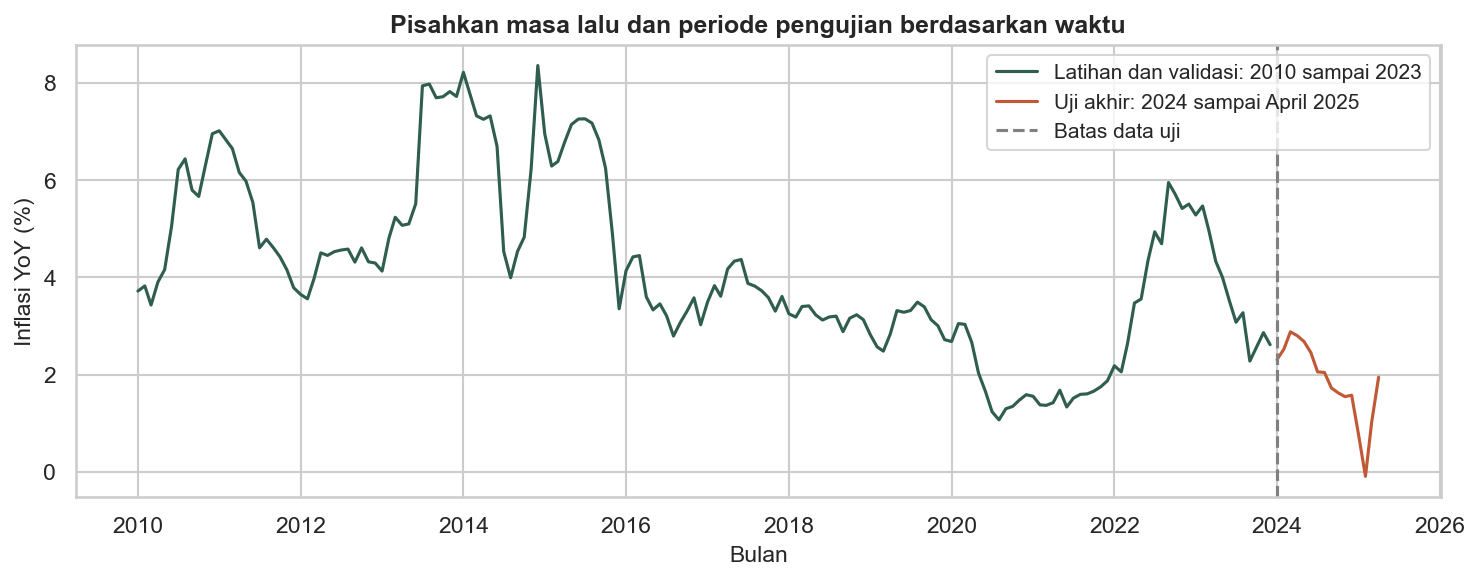

In [23]:
latih_ramalan = inflasi_ramalan.loc[:"2023-12-31"].copy()
uji_ramalan = inflasi_ramalan.loc["2024-01-01":].copy()
X_latih_ramalan = latih_ramalan[["lag_1", "lag_12"]]
y_latih_ramalan = latih_ramalan["inflasi_yoy"]
X_uji_ramalan = uji_ramalan[["lag_1", "lag_12"]]
y_uji_ramalan = uji_ramalan["inflasi_yoy"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(latih_ramalan.index, y_latih_ramalan, color="#2F5D50", label="Latihan dan validasi: 2010 sampai 2023")
ax.plot(uji_ramalan.index, y_uji_ramalan, color="#C15937", label="Uji akhir: 2024 sampai April 2025")
ax.axvline(pd.Timestamp("2024-01-01"), linestyle="--", color="gray", label="Batas data uji")
ax.set_xlabel("Bulan")
ax.set_ylabel("Inflasi YoY (%)")
ax.set_title("Pisahkan masa lalu dan periode pengujian berdasarkan waktu")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Cara membaca:** garis hijau mendahului garis jingga. Model boleh belajar dari
periode hijau; bagian jingga digunakan untuk menilai ramalan setelah rancangan
ditetapkan. Pembagian acak akan mencampurkan urutan ini.

### 2. Periksa tiga tahun validasi sebelum membuka hasil uji

`TimeSeriesSplit` membuat tiga pengujian berurutan, masing-masing 12 bulan.
Latihan bertambah dari satu pengujian ke pengujian berikutnya; seluruh periodenya
tetap sebelum 2024. Data kita berjarak satu bulan sehingga panjang jendelanya sebanding.

`cross_val_score` menjalankan pola latihan dan penilaian tersebut secara otomatis.
Tanda minus di depan mengubah keluaran `neg_mean_absolute_error` menjadi MAE positif.

In [24]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

pembagian_waktu_ramalan = TimeSeriesSplit(n_splits=3, test_size=12)
mae_validasi_ramalan = -cross_val_score(
    LinearRegression(), X_latih_ramalan, y_latih_ramalan,
    cv=pembagian_waktu_ramalan, scoring="neg_mean_absolute_error"
)
hasil_validasi_ramalan = pd.DataFrame({
    "tahun_validasi": [2021, 2022, 2023],
    "MAE_poin_persentase": mae_validasi_ramalan,
})
hasil_validasi_ramalan.round(3)

,tahun_validasi,MAE_poin_persentase
0,2021,0.151
1,2022,0.422
2,2023,0.403


MAE menyatakan rata-rata besar kesalahan tanpa memperhatikan arahnya.
MAE 0,4 berarti ramalan meleset rata-rata 0,4 **poin persentase**, bukan 40%.
Perbedaan MAE antarperiode memperlihatkan bahwa kesulitan meramal dapat berubah.

### 3. Latih model akhir, lalu bandingkan dengan ramalan naif

Model akhir belajar dari seluruh periode latihan sampai Desember 2023.
Ramalan naif menganggap inflasi bulan berikutnya sama dengan inflasi bulan terakhir.
Keduanya diuji pada bulan yang sama dengan informasi masa lalu yang sama.

In [25]:
model_ramalan = LinearRegression()
model_ramalan.fit(X_latih_ramalan, y_latih_ramalan)
prediksi_uji_ramalan = model_ramalan.predict(X_uji_ramalan)
prediksi_naif_ramalan = uji_ramalan["lag_1"]

from sklearn.metrics import mean_absolute_error, root_mean_squared_error

hasil_uji_ramalan = pd.DataFrame({
    "metode": ["Naif: sama dengan bulan lalu", "Regresi: lag 1 dan lag 12"],
    "MAE_poin_persentase": [
        mean_absolute_error(y_uji_ramalan, prediksi_naif_ramalan),
        mean_absolute_error(y_uji_ramalan, prediksi_uji_ramalan),
    ],
    "RMSE_poin_persentase": [
        root_mean_squared_error(y_uji_ramalan, prediksi_naif_ramalan),
        root_mean_squared_error(y_uji_ramalan, prediksi_uji_ramalan),
    ],
})
hasil_uji_ramalan.round(3)

,metode,MAE_poin_persentase,RMSE_poin_persentase
0,Naif: sama dengan bulan lalu,0.372,0.507
1,Regresi: lag 1 dan lag 12,0.419,0.522


### 4. Baca kesalahan pada bulan yang sama

RMSE memberi perhatian lebih besar pada kesalahan besar. Kita tidak memakai
persentase kesalahan relatif (MAPE), karena inflasi dapat mendekati nol atau negatif.

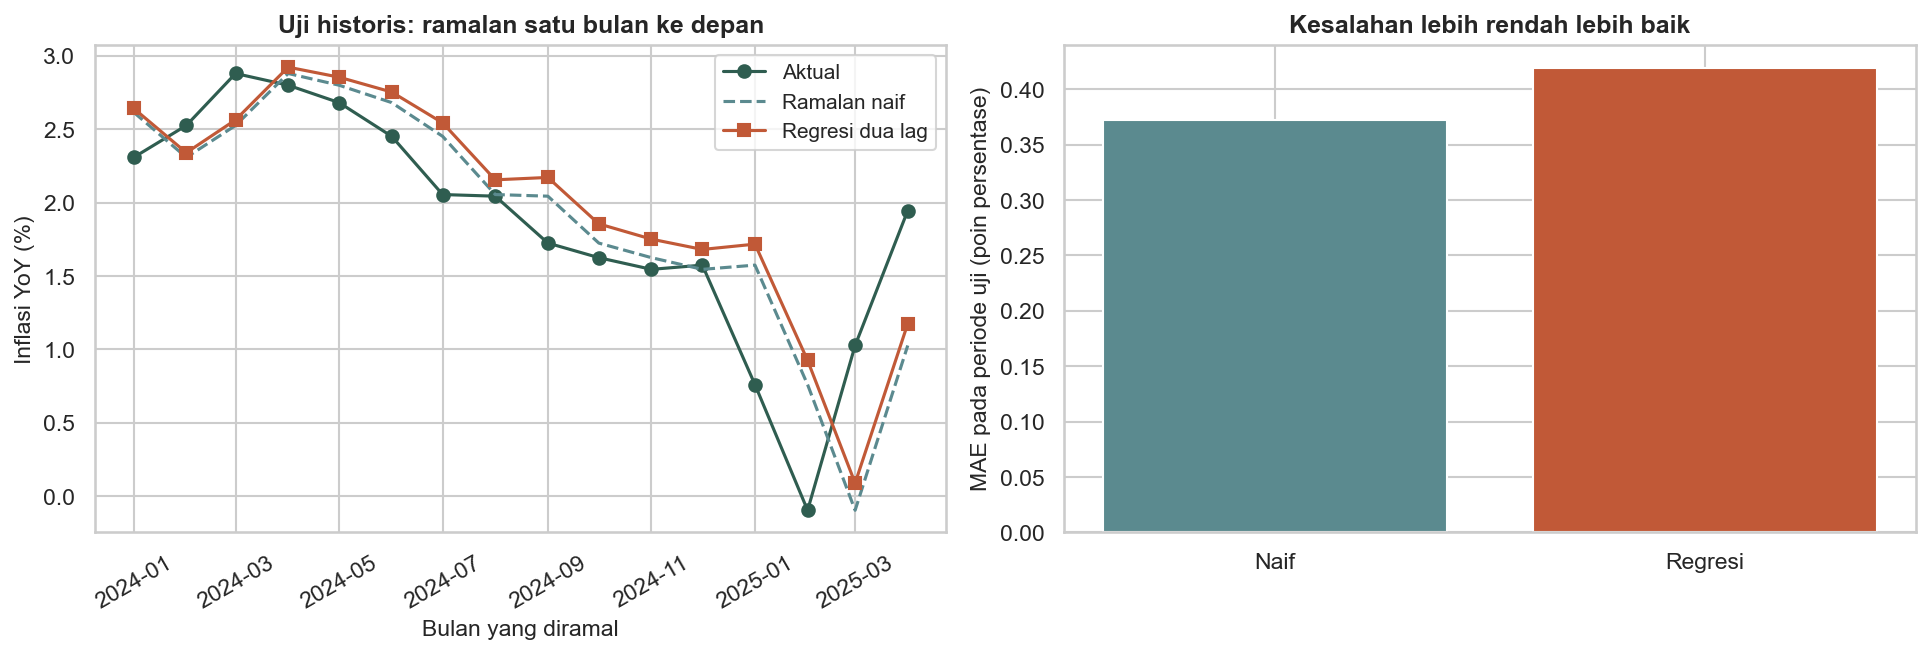

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(y_uji_ramalan.index, y_uji_ramalan, "o-", color="#2F5D50", label="Aktual")
axes[0].plot(y_uji_ramalan.index, prediksi_naif_ramalan, "--", color="#5B8A8F", label="Ramalan naif")
axes[0].plot(y_uji_ramalan.index, prediksi_uji_ramalan, "s-", color="#C15937", label="Regresi dua lag")
axes[0].set_xlabel("Bulan yang diramal")
axes[0].set_ylabel("Inflasi YoY (%)")
axes[0].set_title("Uji historis: ramalan satu bulan ke depan")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
axes[1].bar(["Naif", "Regresi"], hasil_uji_ramalan["MAE_poin_persentase"], color=["#5B8A8F", "#C15937"])
axes[1].set_ylabel("MAE pada periode uji (poin persentase)")
axes[1].set_title("Kesalahan lebih rendah lebih baik")
plt.tight_layout()
plt.show()

**Cara membaca:** lihat kapan ramalan terlambat mengikuti kenaikan atau penurunan
inflasi. Cocokkan dengan batang MAE. Model regresi tidak otomatis mengalahkan
ramalan naif; kesimpulan mengikuti tabel dan periode yang benar-benar diuji.

**Hasil pada periode ini:** MAE naif sekitar 0,372 poin persentase, sedangkan
regresi dua lag sekitar 0,419. Jadi pembanding naif lebih baik pada ukuran MAE
untuk periode uji ini. Tambahan fitur tidak menjamin ramalan membaik.

**Satu bulan ke depan, diulang.** Saat meramal Maret 2024, kita sudah menggunakan
inflasi Februari 2024 yang kemudian teramati; koefisien tetap berasal dari latihan
sampai 2023. Jadi grafik ini bukan ramalan seluruh 16 bulan sekaligus dari Desember 2023.
Ramalan sekaligus memerlukan perlakuan berbeda terhadap fitur masa depan yang belum diketahui.

Uji ini menilai satu rancangan pada satu rentang sejarah. Jangan memilih ulang
model berdasarkan hasil uji akhir dan menyebut angka yang sama sebagai penilaian independen.
Rujukan: [peramalan dengan lag, scikit-learn](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html)
dan [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

### Coba sendiri: pada tahun mana ramalan lebih sulit?

Dari `hasil_validasi_ramalan`, cari tahun dengan MAE paling tinggi dan paling
rendah menggunakan `idxmax` dan `idxmin`. Jelaskan mengapa satu nilai rata-rata
saja belum memperlihatkan perubahan kesulitan meramal antarperiode.
Gunakan satuan poin persentase saat menafsirkan MAE.

In [27]:
# Tulis kode Anda di sini

<details><summary>Lihat petunjuk pembahasan</summary>

Baca tahun dan MAE dari keluaran yang baru dijalankan. Nilai yang berbeda menunjukkan kinerja model berubah antarperiode. Rata-rata merangkum kinerja, tetapi dapat menyembunyikan periode dengan kesalahan besar. Perbedaan ini belum mengidentifikasi penyebabnya.

</details>

## 4. Latihan mandiri

**Latihan 1: ADF dan ARIMA untuk saham.** Data `data/harga_saham_simulasi.csv`.
- Cek ADF di level dan setelah selisih. Stasioner di level atau setelah
  selisih?
- Estimasi ARIMA(1,1,0) dan ramalkan 5 periode.



<!-- kamus_variabel:harga_saham_simulasi.csv -->

### Kenali data: Harga saham simulasi

**Data:** `data/harga_saham_simulasi.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `saham` | Deret harga saham simulasi untuk uji stasioneritas dan peramalan. | Level harga; skala uang tidak dirinci | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [28]:
# saham_ts = pd.read_csv(URL_DATA + "harga_saham_simulasi.csv")
# ...

**Latihan 2: kointegrasi IHSG dan emas.** Data `data/ihsg_emas_simulasi.csv`.
- Jalankan uji `coint(IHSG_Y, Emas_X)`.
- Kalau p < 0,05, estimasi ECM. Kalau tidak, jelaskan kenapa ECM
  sebaiknya tidak dipakai.



<!-- kamus_variabel:ihsg_emas_simulasi.csv -->

### Kenali data: IHSG dan harga emas simulasi

**Data:** `data/ihsg_emas_simulasi.csv`. **Satu baris:** satu bulan berurutan pada contoh simulasi.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Bulan` | Urutan bulan pengamatan. | Nomor bulan; tanggal kalender tidak dicantumkan | Penanda waktu |
| `IHSG_Y` | Indeks Harga Saham Gabungan dalam contoh simulasi. | Poin indeks | Y: target |
| `Emas_X` | Harga emas pada contoh simulasi. | Mata uang dan berat acuan tidak dirinci | X: penjelas |

Tabel ini adalah contoh simulasi; berbeda dari data IHSG harian unduhan Yahoo Finance.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [29]:
# ie = pd.read_csv(URL_DATA + "ihsg_emas_simulasi.csv")
# ...

**Latihan 3: panel retail.** Data `data/panel_toko_ritel.csv`
(5 toko x 10 bulan, `Sales_Y ~ Ads_X1 + Discount_X2`).
- Estimasi CEM (tanpa `entity_effects`) dan FEM (dengan
  `entity_effects=True`).
- Bandingkan koefisien diskon di kedua model. Mana yang Anda percaya
  untuk kebijakan diskon? Kenapa?



<!-- kamus_variabel:panel_toko_ritel.csv -->

### Kenali data: Panel toko ritel

**Data:** `data/panel_toko_ritel.csv`. **Satu baris:** satu cabang toko pada satu bulan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `StoreID` | Kode cabang toko. | Nomor identitas toko | Penanda, bukan besaran ekonomi |
| `Month` | Urutan bulan dalam panel. | Bulan ke-1, ke-2, ... | Penanda waktu |
| `Sales_Y` | Besarnya penjualan toko pada bulan tersebut. | Satuan/skala tidak dirinci sumber | Y: target |
| `Ads_X1` | Biaya iklan cabang toko. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Discount_X2` | Proporsi potongan harga. | Pecahan; 0,10 berarti diskon 10% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [30]:
# retail = pd.read_csv(URL_DATA + "panel_toko_ritel.csv").set_index(["StoreID", "Month"])
# ...

## Selanjutnya

Lanjutkan ke [Lab 06: ekonometrika dengan data Indonesia](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/06_data_indonesia.ipynb). Gunakan nomor yang sama untuk menemukan contoh dan kunci jawaban pada panduan utama.